<a href="https://colab.research.google.com/github/Neethu-Teacher/Assignment-1/blob/main/Assignment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import the required libraries**

In [15]:
# Import necessary libraries

import numpy as np
import pandas as pd

# Dataset
from sklearn.datasets import load_breast_cancer

# Data preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Splitting dataset
from sklearn.model_selection import train_test_split

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


**Load the dataset**

In [16]:
# Load breast cancer dataset

cancer = load_breast_cancer()

# Convert dataset into DataFrame

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Display first five rows

print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

** Check the dataset shape**

In [17]:
print("Dataset shape:", df.shape)
print("Total number of rows:", df.shape[0])
print("Total number of columns:", df.shape[1])

Dataset shape: (569, 30)
Total number of rows: 569
Total number of columns: 30


**Display dataset information**

In [18]:
# Display information about the dataset

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

**Check statistical summary**

In [19]:
# Display statistical summary

print(df.describe())

       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.000000   
25%      

**Check the target variable**

In [20]:
# Display target variable

print("Target names:", cancer.target_names)

print("Target values:", np.unique(cancer.target))

Target names: ['malignant' 'benign']
Target values: [0 1]


**Check class distribution**



In [21]:
# Count the number of samples in each class
print(pd.Series(cancer.target).value_counts())

1    357
0    212
Name: count, dtype: int64


**Check missing values**

In [22]:
# Check missing values in each column
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
Total missing values: 0


** Handle missing values**

In [23]:
# Handle missing values using mean imputation
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(df)
print("Missing values handled successfully!")
print("Shape after imputation:", X.shape)

Missing values handled successfully!
Shape after imputation: (569, 30)


**Split features and target**

In [24]:
# Separate input features and target variable
X = df
y = cancer.target
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


**Feature scaling**

In [25]:
# Apply feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed successfully!")

Feature scaling completed successfully!


**Logistic Regression**

In [26]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=10000)
# Train the model
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


**Make predictions**

In [27]:
# Predict using test data
lr_pred = lr_model.predict(X_test_scaled)
print("Logistic Regression predictions:")
print(lr_pred)

Logistic Regression predictions:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


# ** Calculate accuracy**



In [28]:
# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", lr_accuracy)
print("Accuracy Percentage:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 0.9824561403508771
Accuracy Percentage: 98.24561403508771 %


**Confusion matrix**

In [29]:
# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Confusion Matrix:
[[41  1]
 [ 1 71]]


**Classification report**

In [30]:
# Classification Report
print(classification_report(y_test, lr_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



**Decision Tree Classifier**

In [31]:
from sklearn.tree import DecisionTreeClassifier

# Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model using the pre-scaled training data
dt_model.fit(X_train_scaled, y_train)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [32]:
# Predict using test data
dt_pred = dt_model.predict(X_test_scaled)
print("Decision Tree predictions:")
print(dt_pred)

Decision Tree predictions:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 0 0 0 1
 0 1 0 1 1 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [33]:
from sklearn.metrics import accuracy_score

# Calculate and display accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)
print("Decision Tree Accuracy:", dt_accuracy)
print("Accuracy Percentage:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 0.9122807017543859
Accuracy Percentage: 91.22807017543859 %


In [34]:
from sklearn.metrics import classification_report

# Classification Report for Decision Tree
print("Decision Tree Classification Report:")
print(classification_report(y_test, dt_pred, target_names=cancer.target_names))

Decision Tree Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [35]:
# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Confusion Matrix:
[[39  3]
 [ 7 65]]


**Random Forest Classifier**

In [36]:
# Random Forest Classifier
rf_model = RandomForestClassifier( n_estimators=100,random_state=42)
# Train the model
rf_model.fit(X_train_scaled, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


** Make predictions**

In [37]:
# Predict using test data
rf_pred = rf_model.predict(X_test_scaled)
print("Random Forest predictions:")
print(rf_pred)

Random Forest predictions:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


**Calculate accuracy**

In [38]:
# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy:", rf_accuracy)
print("Accuracy Percentage:", rf_accuracy * 100, "%")

Random Forest Accuracy: 0.956140350877193
Accuracy Percentage: 95.6140350877193 %


**Confusion matrix**

In [39]:
# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Confusion Matrix:
[[39  3]
 [ 2 70]]


 **Classification report**

In [40]:
# Classification Report
print(classification_report(y_test,rf_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



**Support Vector Machine (SVM)**

In [41]:
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled, y_train)
print("SVM model trained successfully!")

SVM model trained successfully!


**Make Predictions**

In [42]:
svm_pred = svm_model.predict(X_test_scaled)
print("SVM predictions:")
print(svm_pred)

SVM predictions:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


**Calculate accuracy**

In [43]:
svm_accuracy = accuracy_score(y_test, svm_pred)
print("SVM Accuracy:", svm_accuracy)
print("Accuracy Percentage:", svm_accuracy * 100, "%")

SVM Accuracy: 0.9736842105263158
Accuracy Percentage: 97.36842105263158 %


**Confusion matrix**

In [44]:
print("SVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

SVM Confusion Matrix:
[[41  1]
 [ 2 70]]


**Classification report**

In [45]:
print("SVM Classification Report:")
print(classification_report( y_test, svm_pred,target_names=cancer.target_names))

SVM Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



**k-Nearest Neighbors (KNN)**

In [46]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
print("KNN model trained successfully!")

KNN model trained successfully!


**Make predictions**

In [47]:
knn_pred = knn_model.predict(X_test_scaled)
print("KNN predictions:")
print(knn_pred)

KNN predictions:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1
 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


**Calculate accuracy**

In [48]:
knn_accuracy = accuracy_score(y_test, knn_pred)
print("KNN Accuracy:", knn_accuracy)
print("Accuracy Percentage:", knn_accuracy * 100, "%")

KNN Accuracy: 0.956140350877193
Accuracy Percentage: 95.6140350877193 %


**Confusion matrix**

In [49]:
print("KNN Confusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

KNN Confusion Matrix:
[[39  3]
 [ 2 70]]


**Classification report**

In [50]:
print("KNN Classification Report:")
print(classification_report(y_test,knn_pred, target_names=cancer.target_names))

KNN Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



**Compare all five algorithms**

In [51]:
results = pd.DataFrame({'Algorithm': ['Logistic Regression','Decision Tree','Random Forest','SVM','KNN' ],'Accuracy': [ lr_accuracy, dt_accuracy, rf_accuracy, svm_accuracy,
        knn_accuracy]})
results['Accuracy Percentage'] = results['Accuracy'] * 100
print(results.sort_values(by='Accuracy', ascending=False))

             Algorithm  Accuracy  Accuracy Percentage
0  Logistic Regression  0.982456            98.245614
3                  SVM  0.973684            97.368421
2        Random Forest  0.956140            95.614035
4                  KNN  0.956140            95.614035
1        Decision Tree  0.912281            91.228070


**Identify the best and worst algorithms**

In [52]:
best_model = results.loc[results['Accuracy'].idxmax()]
worst_model = results.loc[results['Accuracy'].idxmin()]
print("Best performing algorithm:", best_model['Algorithm'])
print("Best accuracy:", best_model['Accuracy Percentage'], "%")
print("Worst performing algorithm:", worst_model['Algorithm'])
print("Worst accuracy:", worst_model['Accuracy Percentage'], "%")

Best performing algorithm: Logistic Regression
Best accuracy: 98.24561403508771 %
Worst performing algorithm: Decision Tree
Worst accuracy: 91.22807017543859 %


**Visualize the comparison**

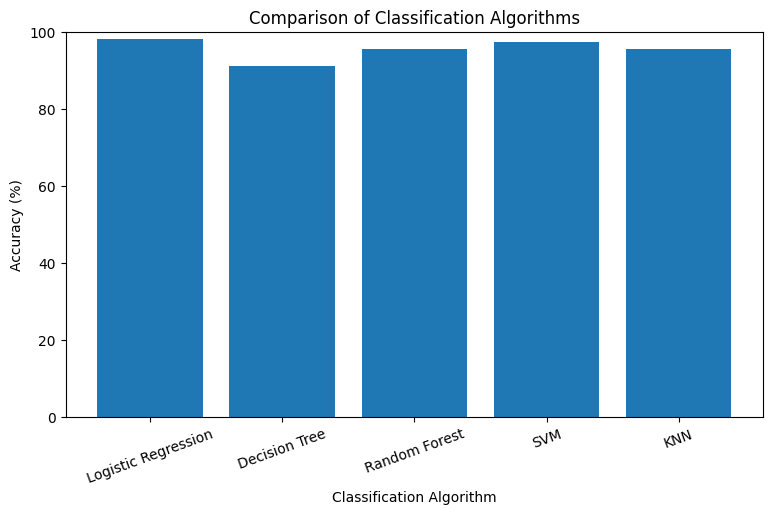

In [53]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.bar(results['Algorithm'],results['Accuracy Percentage'])
plt.xlabel('Classification Algorithm')
plt.ylabel('Accuracy (%)')
plt.title('Comparison of Classification Algorithms')
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.show()

# Assignment conclusion

In [54]:
print("Conclusion:")
print("Five classification algorithms were implemented")
print("using the breast cancer dataset.")
print("Their performance was compared using accuracy.")
print("The best and worst performing algorithms were identified.")

Conclusion:
Five classification algorithms were implemented
using the breast cancer dataset.
Their performance was compared using accuracy.
The best and worst performing algorithms were identified.


# **Conclusion**

The breast cancer dataset from the Scikit-learn library was successfully loaded and used to implement five supervised machine learning classification algorithms: Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (SVM), and k-Nearest Neighbors (KNN).

During preprocessing, the dataset was checked for missing values, and feature scaling was performed using StandardScaler to bring the numerical features to a similar scale. The dataset was then divided into training and testing sets.

All five classification models were trained and evaluated using accuracy score, confusion matrix, and classification report. Their performances were compared to identify the best and worst performing algorithms.

This assignment helped me understand the working principles of different classification algorithms and how machine learning techniques can be applied to classify breast cancer tumours as malignant or benign.

Note: After running your comparison table, add this sentence with your actual results:

"The [Logestic Regrssion] achieved the highest accuracy of [98.24561403508771 %]%, while the [Decision tree] achieved the lowest accuracy of [91.22807017543859 %]%."